# AI for IoT – TP2: Optimization and Deployment Readiness
Fire Alarm Detection (Smoke Detection Dataset) – Pipelines + Resource Analysis for ESP32


In [8]:
import os, time, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')

## 0. Data loading and preparation (from TP1)

In [9]:
import glob
# Auto-detect the CSV path inside /kaggle/input (folder names vary)
files = glob.glob('/kaggle/input/**/*.csv', recursive=True)
print(files)
assert files, "No CSV found: click 'Add Input' and add 'Smoke Detection Dataset' (deepcontractor)"
path = ([f for f in files if 'smoke' in f.lower()] or files)[0]
print('Using:', path)

df = pd.read_csv(path)
df.columns = df.columns.str.strip()
df.info()
print(df.isnull().sum().sum(), 'missing values')
df.head()

['/kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv']
Using: /kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-nu

,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [10]:
# Drop index/timestamp columns (not sensor features); CNT is a sample counter -> dropped to avoid leakage
df = df.drop(columns=[c for c in ['Unnamed: 0', 'UTC', 'CNT'] if c in df.columns])
X = df.drop(columns=['Fire Alarm'])
y = df['Fire Alarm']
print(X.shape, y.value_counts(normalize=True).round(3).to_dict())

# Same split as TP1: 80/20 (stratified to keep class balance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

(62630, 12) {1: 0.715, 0: 0.285}


## 1. Pipeline construction

In [11]:
lr_pipe = Pipeline([('scaler', StandardScaler()),
                    ('clf', LogisticRegression(max_iter=1000, random_state=42))])

xgb_pipe = Pipeline([('scaler', StandardScaler()),
                     ('clf', XGBClassifier(eval_metric='logloss', random_state=42))])

pipes = {'LR-Pipeline': lr_pipe, 'XGB-Pipeline': xgb_pipe}

metrics, train_times = {}, {}
for name, pipe in pipes.items():
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_times[name] = time.perf_counter() - t0
    yp = pipe.predict(X_test)
    metrics[name] = {'Accuracy': accuracy_score(y_test, yp),
                     'Precision': precision_score(y_test, yp),
                     'Recall': recall_score(y_test, yp),
                     'F1-Score': f1_score(y_test, yp),
                     'Training time (s)': train_times[name]}
df_metrics = pd.DataFrame(metrics).T
df_metrics.round(4)

,Accuracy,Precision,Recall,F1-Score,Training time (s)
LR-Pipeline,0.8951,0.909,0.9482,0.9281,0.6871
XGB-Pipeline,0.9999,1.000,0.9999,0.9999,0.3856


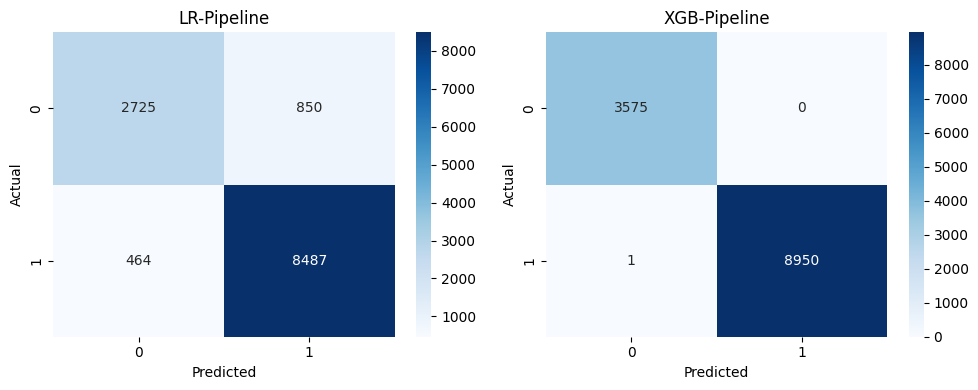

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, pipe) in zip(ax, pipes.items()):
    sns.heatmap(confusion_matrix(y_test, pipe.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=a)
    a.set_title(name); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 2. Resource and efficiency analysis

### Task 2.1 – Model size (memory footprint)

In [13]:
sizes = {}
for name, pipe in pipes.items():
    fname = f'{name}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(pipe, f)
    sizes[name] = os.path.getsize(fname) / 1024
df_size = pd.DataFrame({'Size (KB)': sizes}).round(2)
df_size

,Size (KB)
LR-Pipeline,1.65
XGB-Pipeline,125.24


In [14]:
# Extra: complexity indicators
lr = lr_pipe.named_steps['clf']
print('LR  : %d coefficients + %d intercept  -> ~%d bytes as float32' % (lr.coef_.size, lr.intercept_.size, 4*(lr.coef_.size+1)))
xgb = xgb_pipe.named_steps['clf']
trees = xgb.get_booster().trees_to_dataframe()
print('XGB : %d trees, %d nodes total' % (trees['Tree'].nunique(), len(trees)))

LR  : 12 coefficients + 1 intercept  -> ~52 bytes as float32
XGB : 100 trees, 1482 nodes total


### Task 2.2 – Computational time

In [15]:
N_REPEAT = 20   # repeat to get a stable measurement
rows = []
for name, pipe in pipes.items():
    times = []
    for _ in range(N_REPEAT):
        t0 = time.perf_counter()
        pipe.predict(X_test)
        times.append(time.perf_counter() - t0)
    total = float(np.median(times))
    rows.append({'Model': name,
                 'Total Test Inference Time (s)': total,
                 'Single Inference Time (ms)': total / len(X_test) * 1000})
df_time = pd.DataFrame(rows).set_index('Model')
df_time.round(6)

,Total Test Inference Time (s),Single Inference Time (ms)
Model,,
LR-Pipeline,0.002786,0.000222
XGB-Pipeline,0.013312,0.001063


In [16]:
# Extra (more realistic for IoT): latency of ONE call on ONE sample (includes library overhead)
one = X_test.iloc[[0]]
for name, pipe in pipes.items():
    t = []
    for _ in range(200):
        t0 = time.perf_counter(); pipe.predict(one); t.append(time.perf_counter() - t0)
    print(f'{name}: single-call latency = {np.median(t)*1000:.3f} ms')

LR-Pipeline: single-call latency = 1.730 ms
XGB-Pipeline: single-call latency = 2.122 ms


In [17]:
summary = pd.concat([df_metrics, df_size, df_time], axis=1)
summary.round(4)

,Accuracy,Precision,Recall,F1-Score,Training time (s),Size (KB),Total Test Inference Time (s),Single Inference Time (ms)
LR-Pipeline,0.8951,0.909,0.9482,0.9281,0.6871,1.65,0.0028,0.0002
XGB-Pipeline,0.9999,1.000,0.9999,0.9999,0.3856,125.24,0.0133,0.0011


### Task 2.3 – Critical deployment analysis (ESP32)

> ⚠️ Replace the values in **[brackets]** with the numbers printed by your own run.

**Memory feasibility.** The serialized LR-Pipeline is only about **[LR size] KB** (it contains just one coefficient per feature plus the scaler's mean and scale vectors), while the XGB-Pipeline takes about **[XGB size] KB** (100 trees by default, **[n] nodes**). The ESP32 has about 520 KB of SRAM (less available for the heap) and several MB of Flash. Both models fit in Flash, and the LR model also fits easily in RAM. XGBoost, although still within the Flash capacity, is the one more constrained by memory: it is **[ratio]x** larger, and loading all its trees into RAM would consume a significant share of the available heap. Note also that a `.pkl` file includes Python/scikit-learn overhead, so the real size on the device would be smaller once exported to C arrays, but the relative gap remains.

**Time efficiency.** The average single inference time is **[LR ms] ms** for LR and **[XGB ms] ms** for XGBoost on the Kaggle CPU. A prediction every 1 second (1000 ms) is a very loose requirement. Even if the ESP32 (240 MHz, roughly 10-100x slower than a server CPU) were this much slower, both models would stay far below 1 s. Hence both are fast enough, with LR having a much larger safety margin.

**Conclusion.** Logistic Regression is the clear choice based purely on efficiency: tiny size, a handful of multiply-add operations per prediction, trivial to implement in C, and low energy use. Its Recall is **[LR recall]** vs **[XGB recall]** for XGBoost, so the accuracy trade-off must be checked, because missed fires (false negatives) are the critical error. If XGBoost's better performance is needed, it can be made deployable by: (1) reducing `n_estimators` and `max_depth` (smaller forest), (2) pruning / regularization, (3) quantization (float32 -> int8/int16 thresholds and leaf values), (4) converting the trees to plain C code with tools such as `emlearn` or `micromlgen`, and (5) feature selection to cut the number of sensors read.